# Tugas IPSD: Klasifikasi Citra Penyakit Daun Tomat (6 Kelas) dengan 5-Fold Cross Validation
**Dataset:** PlantVillage (6 kelas daun tomat) | **Metode:** 5-Fold CV | **Model:** Simple CNN, Modified CNN, InceptionV3

| Soal | Dijawab oleh bagian |
|---|---|
| 1. Karakteristik distribusi data tiap kelas | Bagian 3 (diagram batang) |
| 2. Preprocessing dan pengaruhnya | Bagian 4 (contoh augmentasi) + perbandingan hasil |
| 3. Apakah model mampu mengklasifikasikan keenam kelas dengan baik | Bagian 8 (heatmap, F1 per kelas) |
| 4. Kelas yang paling sering salah | Bagian 8 (heatmap, daftar kesalahan terbanyak) |
| 5. Hasil evaluasi tiap fold | Bagian 6 (kurva loss/accuracy, tabel per fold) |
| 6. Rata-rata evaluasi 5 fold | Bagian 7 (tabel mean ± std, grafik perbandingan) |
| 7. Kelebihan dan keterbatasan | Bagian 9 (ringkasan angka untuk bahan jawaban) |

Aktifkan GPU dulu: Runtime > Change runtime type > T4 GPU.

## 1. Download dataset (hanya kelas tomat)
Token Kaggle diambil dari Colab Secrets (`KAGGLE_TOKEN`), jangan ditulis langsung di notebook.

In [ ]:
import os
from google.colab import userdata
os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
p = os.path.expanduser('~/.kaggle/access_token')
open(p, 'w').write(userdata.get('KAGGLE_TOKEN'))
os.chmod(p, 0o600)

!kaggle datasets download -d abdallahalidev/plantvillage-dataset
!unzip -q plantvillage-dataset.zip "plantvillage dataset/color/Tomato___*" -d dataset_daun/
!ls "dataset_daun/plantvillage dataset/color"

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:22<00:00, 95.8MB/s]

 Tomato___Bacterial_spot   Tomato___Septoria_leaf_spot
 Tomato___Early_blight	  'Tomato___Spider_mites Two-spotted_spider_mite'
 Tomato___healthy	   Tomato___Target_Spot
 Tomato___Late_blight	   Tomato___Tomato_mosaic_virus
 Tomato___Leaf_Mold	   Tomato___Tomato_Yellow_Leaf_Curl_Virus


## 2. Modul preprocessing dan arsitektur model
Sama dengan notebook sebelumnya (`preprocessing.py` dan `models_hub.py`).

In [ ]:
%%writefile preprocessing.py
import os
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def load_data_paths(base_dir):
    filepaths, labels = [], []
    for folder in os.listdir(base_dir):
        folder_path = os.path.join(base_dir, folder)
        if os.path.isdir(folder_path):
            for file in os.listdir(folder_path):
                filepaths.append(os.path.join(folder_path, file))
                labels.append(folder)
    return pd.DataFrame({'filepath': filepaths, 'label': labels})

def get_data_generators():
    train_datagen = ImageDataGenerator(
        rescale=1./255, rotation_range=20, width_shift_range=0.2,
        height_shift_range=0.2, horizontal_flip=True
    )
    val_datagen = ImageDataGenerator(rescale=1./255)
    return train_datagen, val_datagen

Writing preprocessing.py


In [ ]:
%%writefile models_hub.py
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import InceptionV3
import tensorflow.keras.backend as K

def f1_score(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
    precision = true_positives / (predicted_positives + K.epsilon())
    recall = true_positives / (possible_positives + K.epsilon())
    return 2 * (precision * recall) / (precision + recall + K.epsilon())

def compile_and_return(model):
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy',
                           tf.keras.metrics.Precision(name='precision'),
                           tf.keras.metrics.Recall(name='recall'),
                           tf.keras.metrics.AUC(name='auc'),
                           f1_score])
    return model

# ALGORITMA 1: Simple CNN
def build_algo1_simple_cnn(input_shape=(128, 128, 3), num_classes=38):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax', dtype='float32')
    ])
    return compile_and_return(model)

# ALGORITMA 2: Modified CNN
def build_algo2_modified_cnn(input_shape=(128, 128, 3), num_classes=38):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax', dtype='float32')
    ])
    return compile_and_return(model)

# ALGORITMA 3: Transfer Learning (InceptionV3)
def build_algo3_inceptionv3(input_shape=(128, 128, 3), num_classes=38):
    base = InceptionV3(input_shape=input_shape, include_top=False, weights='imagenet')
    base.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)

    model = models.Model(inputs, outputs)
    return compile_and_return(model)

Writing models_hub.py


In [ ]:
import sys, json, random
sys.path.append('.')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_recall_fscore_support, accuracy_score)
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

from preprocessing import load_data_paths, get_data_generators
from models_hub import build_algo1_simple_cnn, build_algo2_modified_cnn, build_algo3_inceptionv3

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("GPU:", tf.config.list_physical_devices('GPU'))

BASE_DIR = "dataset_daun/plantvillage dataset/color"
KELAS = ["Tomato___Bacterial_spot", "Tomato___Early_blight", "Tomato___Late_blight",
         "Tomato___Leaf_Mold", "Tomato___Septoria_leaf_spot", "Tomato___healthy"]   # ubah di sini jika 6 kelas ditentukan lain
IMG, BATCH, EPOCHS, N_FOLD = (128, 128), 32, 10, 5
ALGOS = [1, 2, 3]            # kurangi (mis. [3]) kalau ingin lebih cepat
NAMA = {1: 'Simple CNN', 2: 'Modified CNN', 3: 'InceptionV3'}

def bersih(n): return n.replace('Tomato___', '').replace('_', ' ')

df = load_data_paths(BASE_DIR)
df = df[df['label'].isin(KELAS)].sort_values('filepath').reset_index(drop=True)
class_names = sorted(KELAS)
short = [bersih(c) for c in class_names]
print(len(df), "gambar,", df['label'].nunique(), "kelas")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
9350 gambar, 6 kelas


## 3. Soal 1 - Distribusi data per kelas

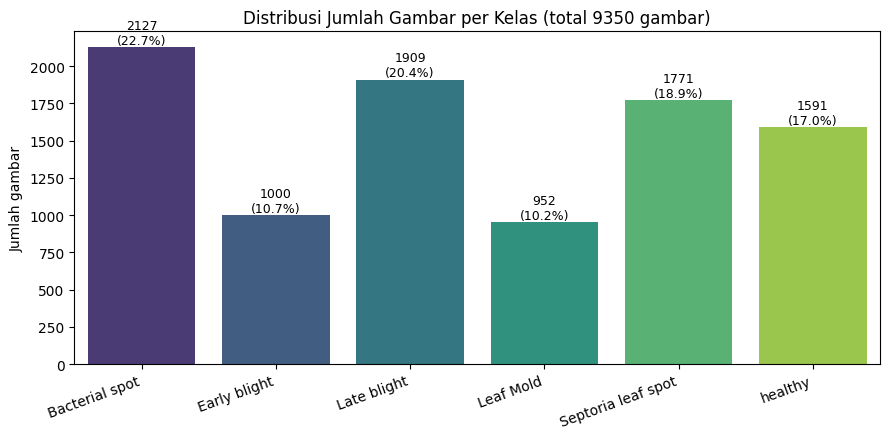

Kelas terbanyak : Bacterial spot 2127
Kelas tersedikit: Leaf Mold 952
Rasio terbanyak : tersedikit = 2.23 : 1


In [ ]:
counts = df['label'].value_counts().reindex(class_names)
pct = counts / counts.sum() * 100

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(x=short, y=counts.values, hue=short, palette="viridis", legend=False)
for i, (c, p_) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c + counts.max()*0.01, f"{c}\n({p_:.1f}%)", ha='center', fontsize=9)
ax.set_title(f"Distribusi Jumlah Gambar per Kelas (total {counts.sum()} gambar)")
ax.set_ylabel("Jumlah gambar"); ax.set_xlabel("")
plt.xticks(rotation=20, ha='right'); plt.tight_layout()
plt.savefig("fig1_distribusi.png", dpi=150); plt.show()

print("Kelas terbanyak :", short[int(np.argmax(counts.values))], counts.max())
print("Kelas tersedikit:", short[int(np.argmin(counts.values))], counts.min())
print("Rasio terbanyak : tersedikit =", round(counts.max()/counts.min(), 2), ": 1")

## 4. Soal 2 - Preprocessing
Preprocessing: resize 128x128, normalisasi piksel (rescale 1/255), dan augmentasi pada data latih (rotasi 20°, geser 20%, flip horizontal). Data uji hanya di-rescale.

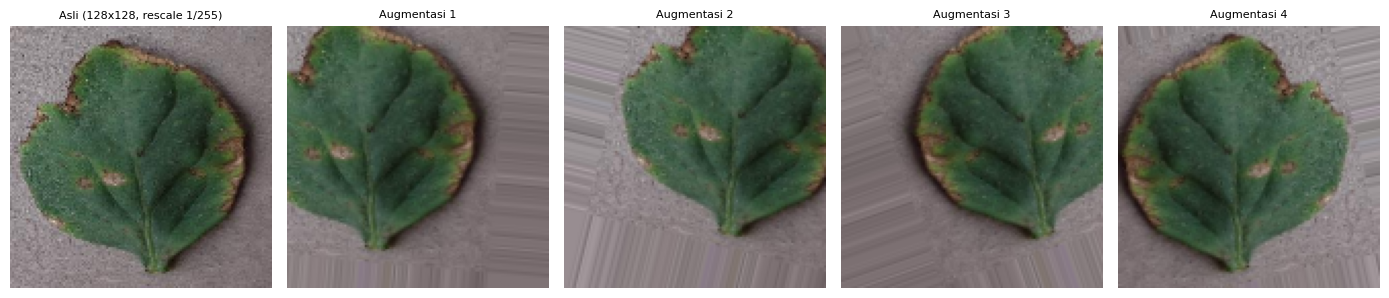

In [ ]:
train_dg, val_dg = get_data_generators()
path = df.sample(1, random_state=3)['filepath'].iloc[0]
img = tf.keras.utils.img_to_array(tf.keras.utils.load_img(path, target_size=IMG)) / 255.0

fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(img); axes[0].set_title("Asli (128x128, rescale 1/255)", fontsize=8)
for i in range(1, 5):
    axes[i].imshow(np.clip(train_dg.random_transform(img), 0, 1)); axes[i].set_title(f"Augmentasi {i}", fontsize=8)
for a in axes: a.axis('off')
plt.tight_layout(); plt.savefig("fig2_preprocessing.png", dpi=150); plt.show()

## 5. Training 5-Fold Cross Validation
Tiap fold: 1 bagian jadi data uji, 4 bagian untuk training (90% latih, 10% validasi untuk early stopping). Hasil tiap algoritma disimpan ke `hasil_algoN.json`; kalau sesi terputus, jalankan ulang sel ini dan algoritma yang sudah selesai akan dilewati (salin file json ke Google Drive agar aman).

In [ ]:
BUILD = {1: build_algo1_simple_cnn, 2: build_algo2_modified_cnn, 3: build_algo3_inceptionv3}
skf = StratifiedKFold(n_splits=N_FOLD, shuffle=True, random_state=SEED)
folds = list(skf.split(df['filepath'], df['label']))
common = dict(x_col='filepath', y_col='label', target_size=IMG, batch_size=BATCH,
              class_mode='categorical', classes=class_names)
RESULT = {}

for algo in ALGOS:
    fn = f"hasil_algo{algo}.json"
    if os.path.exists(fn):
        RESULT[algo] = json.load(open(fn)); print(f"{NAMA[algo]}: dimuat dari {fn}"); continue

    res = {"hist": [], "fold": [], "y_true": [], "y_pred": []}
    for k, (tr_idx, te_idx) in enumerate(folds, start=1):
        print(f"\n===== {NAMA[algo]} - Fold {k}/{N_FOLD} =====")
        tf.keras.backend.clear_session()
        tr_df, te_df = df.iloc[tr_idx], df.iloc[te_idx]
        tr_df, va_df = train_test_split(tr_df, test_size=0.1, stratify=tr_df['label'], random_state=SEED)

        train_dg, val_dg = get_data_generators()
        tr_gen = train_dg.flow_from_dataframe(tr_df, shuffle=True, **common)
        va_gen = val_dg.flow_from_dataframe(va_df, shuffle=False, **common)
        te_gen = val_dg.flow_from_dataframe(te_df, shuffle=False, **common)

        model = BUILD[algo](input_shape=IMG + (3,), num_classes=len(class_names))
        cb = [ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
              EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)]
        h = model.fit(tr_gen, validation_data=va_gen, epochs=EPOCHS, callbacks=cb, verbose=2)

        ev = model.evaluate(te_gen, return_dict=True, verbose=0)
        y_pred = model.predict(te_gen, verbose=0).argmax(axis=1)
        y_true = te_gen.classes
        p_, r_, f_, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
        row = {"Fold": k, "Loss": float(ev['loss']), "Accuracy": float(accuracy_score(y_true, y_pred)),
               "Precision": float(p_), "Recall": float(r_), "F1": float(f_), "AUC": float(ev['auc'])}
        print(row)
        res["fold"].append(row)
        res["hist"].append({kk: [float(x) for x in v] for kk, v in h.history.items()
                            if kk in ('loss', 'val_loss', 'accuracy', 'val_accuracy')})
        res["y_true"] += [int(x) for x in y_true]; res["y_pred"] += [int(x) for x in y_pred]

    json.dump(res, open(fn, 'w')); RESULT[algo] = res
print("\nSelesai.")


===== Simple CNN - Fold 1/5 =====
Found 6732 validated image filenames belonging to 6 classes.
Found 748 validated image filenames belonging to 6 classes.
Found 1870 validated image filenames belonging to 6 classes.
Epoch 1/10
211/211 - 61s - 291ms/step - accuracy: 0.5386 - auc: 0.8480 - f1_score: 0.3878 - loss: 1.2151 - precision: 0.7785 - recall: 0.3012 - val_accuracy: 0.4666 - val_auc: 0.7838 - val_f1_score: 0.4255 - val_loss: 1.7291 - val_precision: 0.5161 - val_recall: 0.3650 - learning_rate: 3.0000e-04
Epoch 2/10
211/211 - 40s - 191ms/step - accuracy: 0.7285 - auc: 0.9473 - f1_score: 0.7090 - loss: 0.7355 - precision: 0.8110 - recall: 0.6337 - val_accuracy: 0.5869 - val_auc: 0.8569 - val_f1_score: 0.5693 - val_loss: 1.4368 - val_precision: 0.6270 - val_recall: 0.5214 - learning_rate: 3.0000e-04
Epoch 3/10
211/211 - 39s - 187ms/step - accuracy: 0.7757 - auc: 0.9645 - f1_score: 0.7684 - loss: 0.5972 - precision: 0.8368 - recall: 0.7136 - val_accuracy: 0.6671 - val_auc: 0.9114 - va

## 6. Soal 5 - Hasil tiap fold
Kurva accuracy (kiri) dan loss (kanan) untuk tiap fold, lalu tabel metrik per fold. Metrik Precision, Recall, F1 memakai rata-rata makro antar kelas.

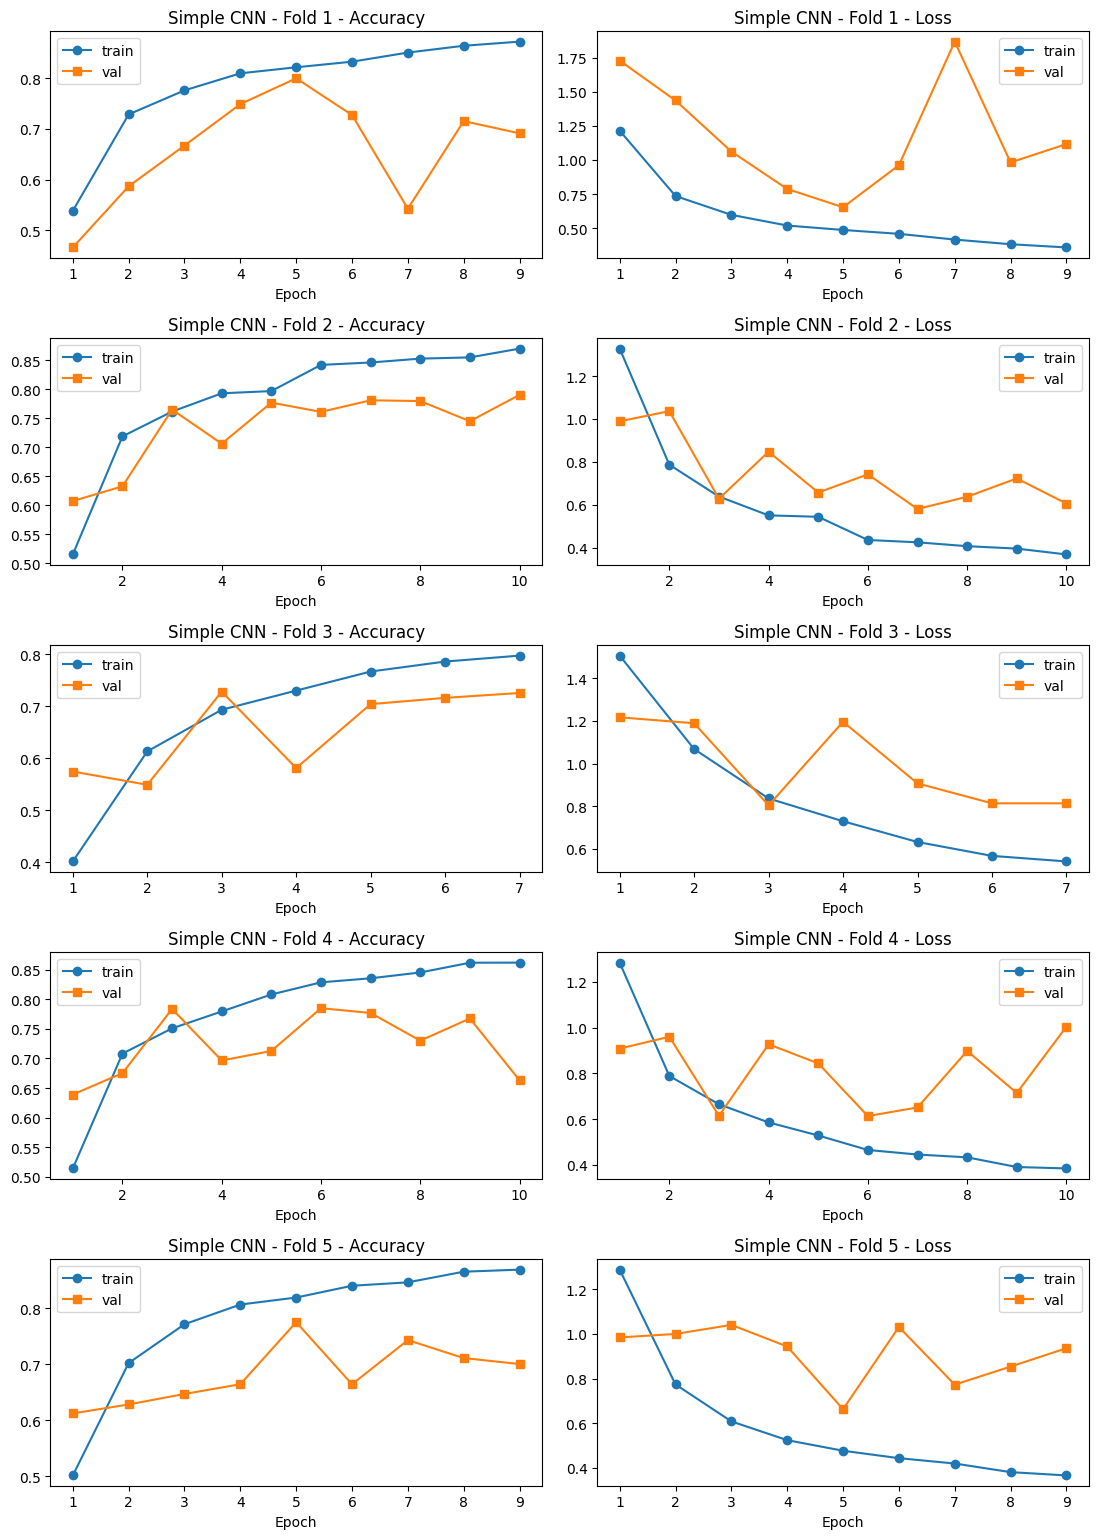

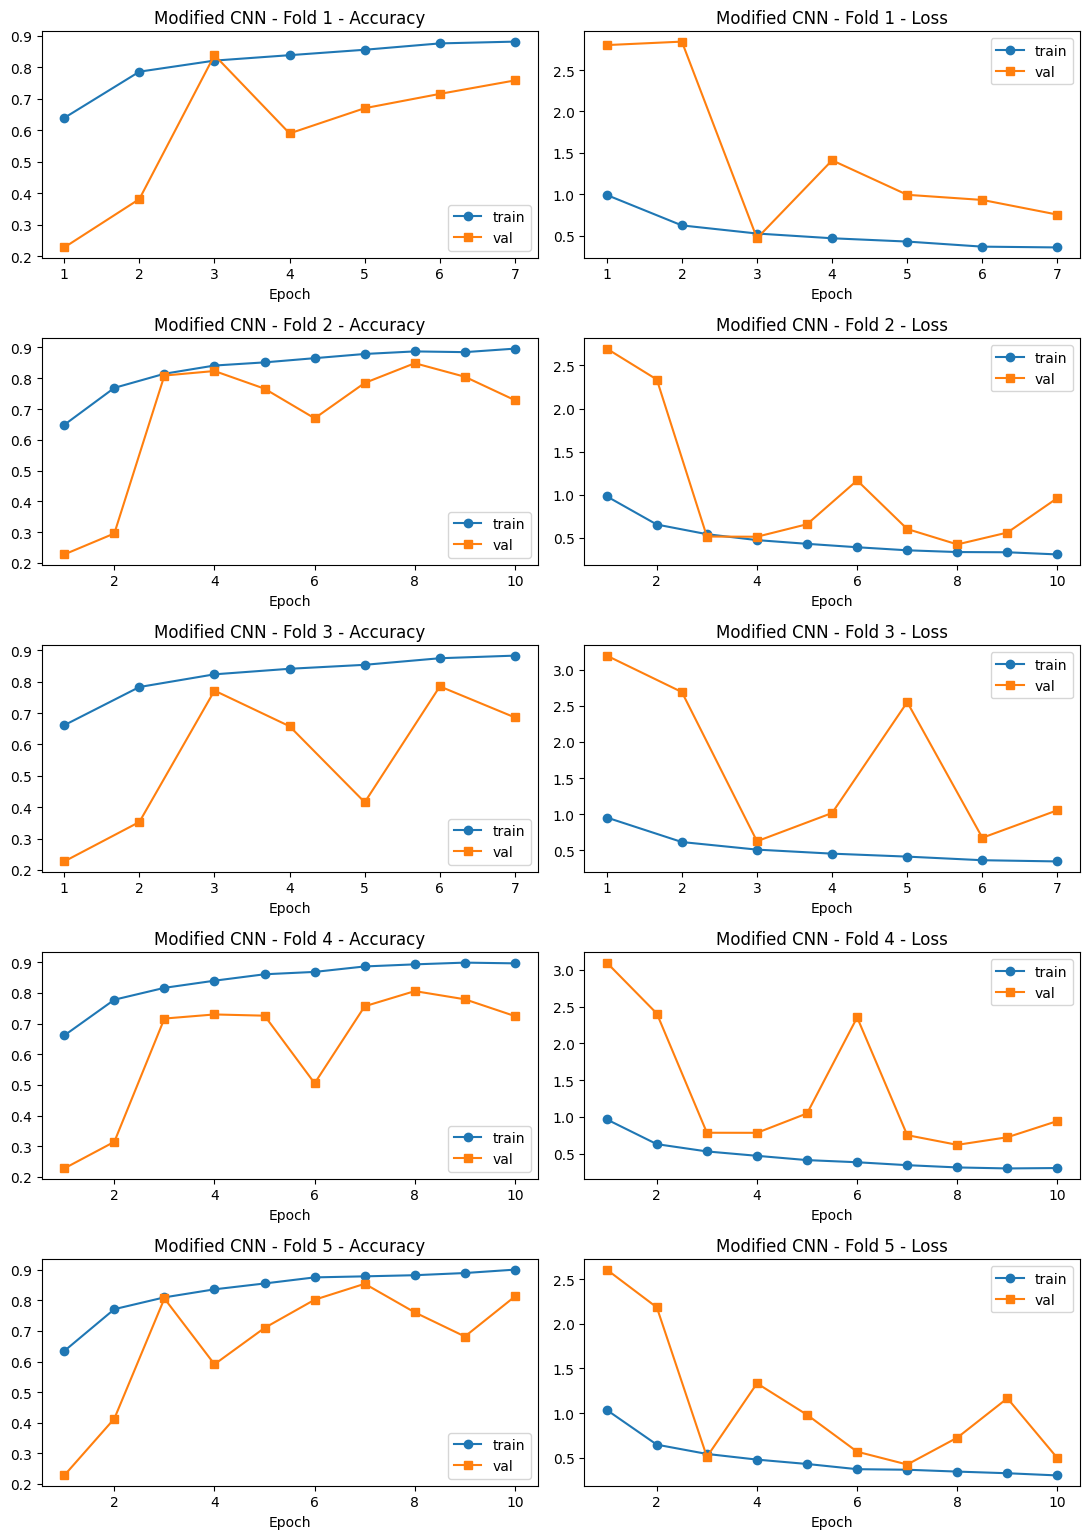

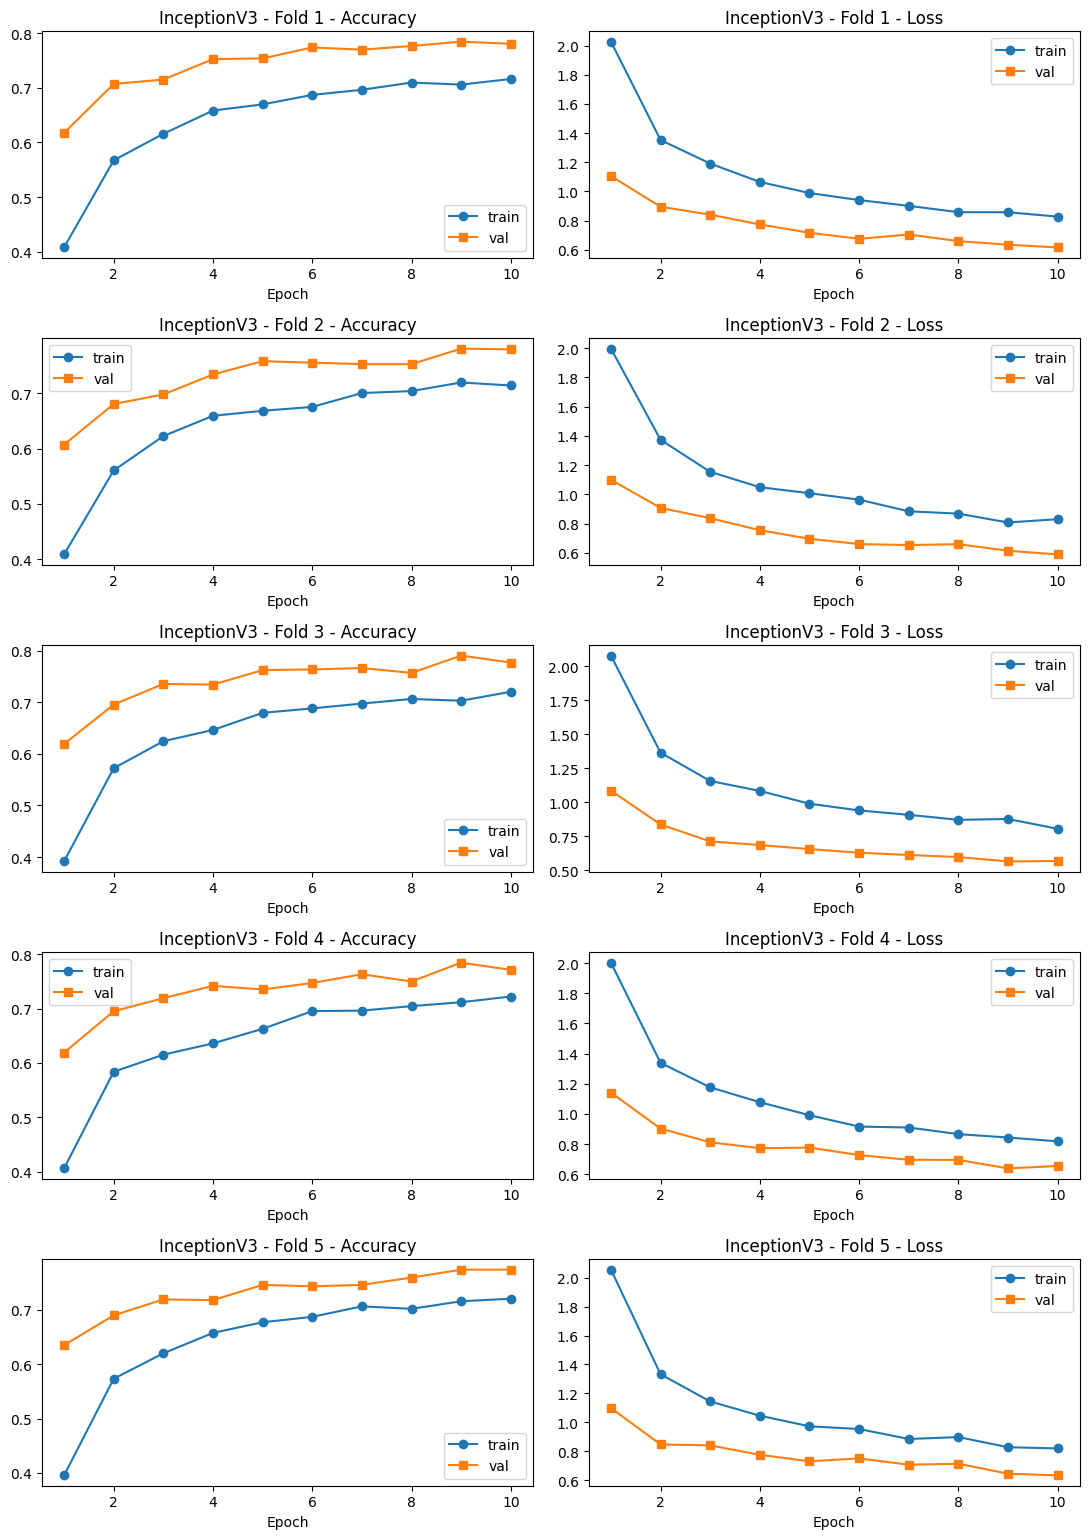


=== Simple CNN: hasil per fold (data uji) ===


,Loss,Accuracy,Precision,Recall,F1,AUC
Fold,,,,,,
1,0.6291,0.7781,0.7753,0.7353,0.7393,0.9614
2,0.5940,0.7914,0.8103,0.7701,0.7708,0.9640
3,0.8186,0.7144,0.7574,0.6565,0.6610,0.9375
4,0.5821,0.7920,0.7635,0.7585,0.7565,0.9651
5,0.6101,0.7968,0.8006,0.7670,0.7711,0.9621



=== Modified CNN: hasil per fold (data uji) ===


,Loss,Accuracy,Precision,Recall,F1,AUC
Fold,,,,,,
1,0.5076,0.8150,0.8203,0.7693,0.7803,0.9739
2,0.4229,0.8481,0.8391,0.8422,0.8308,0.9807
3,0.6172,0.7738,0.7746,0.7480,0.7488,0.9617
4,0.6103,0.8257,0.8509,0.7827,0.7917,0.9639
5,0.4180,0.8524,0.8529,0.8375,0.8401,0.9804



=== InceptionV3: hasil per fold (data uji) ===


,Loss,Accuracy,Precision,Recall,F1,AUC
Fold,,,,,,
1,0.6213,0.7727,0.7557,0.7474,0.7501,0.9599
2,0.6252,0.7840,0.7741,0.7572,0.7615,0.9600
3,0.6225,0.7775,0.7638,0.7516,0.7559,0.9604
4,0.6263,0.7743,0.7674,0.7396,0.7475,0.9596
5,0.6165,0.7770,0.7601,0.7534,0.7510,0.9613


In [ ]:
def plot_curves(algo):
    H = RESULT[algo]['hist']
    fig, axes = plt.subplots(len(H), 2, figsize=(11, 3.1 * len(H)))
    for r, h in enumerate(H):
        ep = range(1, len(h['loss']) + 1)
        axes[r, 0].plot(ep, h['accuracy'], 'o-', label='train'); axes[r, 0].plot(ep, h['val_accuracy'], 's-', label='val')
        axes[r, 0].set_title(f"{NAMA[algo]} - Fold {r+1} - Accuracy"); axes[r, 0].legend(); axes[r, 0].set_xlabel("Epoch")
        axes[r, 1].plot(ep, h['loss'], 'o-', label='train'); axes[r, 1].plot(ep, h['val_loss'], 's-', label='val')
        axes[r, 1].set_title(f"{NAMA[algo]} - Fold {r+1} - Loss"); axes[r, 1].legend(); axes[r, 1].set_xlabel("Epoch")
    plt.tight_layout(); plt.savefig(f"fig3_kurva_algo{algo}.png", dpi=130); plt.show()

for a in RESULT: plot_curves(a)

metrik = ["Loss", "Accuracy", "Precision", "Recall", "F1", "AUC"]
rows = [{"Algoritma": NAMA[a], **d} for a in RESULT for d in RESULT[a]['fold']]
tab = pd.DataFrame(rows)
for a in RESULT:
    print(f"\n=== {NAMA[a]}: hasil per fold (data uji) ===")
    display(tab[tab.Algoritma == NAMA[a]].set_index("Fold")[metrik].round(4))
tab.to_csv("hasil_per_fold.csv", index=False)

## 7. Soal 6 - Rata-rata 5 fold

=== Rata-rata ± standar deviasi 5 fold ===


,Loss,Accuracy,Precision,Recall,F1,AUC
Algoritma,,,,,,
Simple CNN,0.6468 ± 0.0976,0.7745 ± 0.0343,0.7814 ± 0.0231,0.7375 ± 0.0473,0.7397 ± 0.0459,0.958 ± 0.0116
Modified CNN,0.5152 ± 0.0968,0.823 ± 0.0316,0.8276 ± 0.0323,0.7959 ± 0.042,0.7984 ± 0.0375,0.9721 ± 0.0089
InceptionV3,0.6224 ± 0.0039,0.7771 ± 0.0043,0.7642 ± 0.007,0.7498 ± 0.0067,0.7532 ± 0.0055,0.9603 ± 0.0006


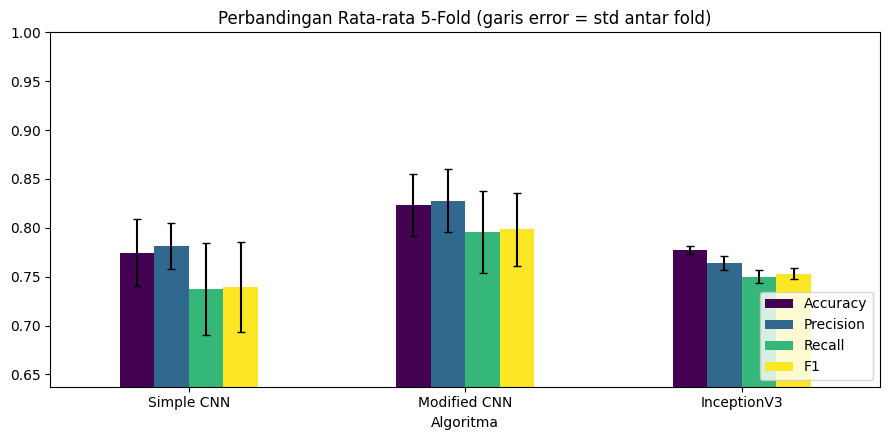

In [ ]:
urut = [NAMA[a] for a in RESULT]
mean_ = tab.groupby("Algoritma")[metrik].mean().loc[urut]
std_ = tab.groupby("Algoritma")[metrik].std().loc[urut]
ringkas = mean_.round(4).astype(str) + " ± " + std_.round(4).astype(str)
print("=== Rata-rata ± standar deviasi 5 fold ==="); display(ringkas)
mean_.to_csv("hasil_rata_rata.csv")

m = ["Accuracy", "Precision", "Recall", "F1"]
mean_[m].plot(kind='bar', yerr=std_[m], capsize=3, figsize=(9, 4.5), rot=0, colormap='viridis')
plt.ylim(max(0, mean_[m].min().min() - 0.1), 1.0)
plt.title("Perbandingan Rata-rata 5-Fold (garis error = std antar fold)")
plt.legend(loc='lower right'); plt.tight_layout(); plt.savefig("fig4_perbandingan.png", dpi=150); plt.show()

## 8. Soal 3 dan 4 - Confusion matrix (heatmap), F1 per kelas, kelas yang sering salah
Prediksi dari seluruh fold digabung, sehingga setiap gambar diuji tepat satu kali.

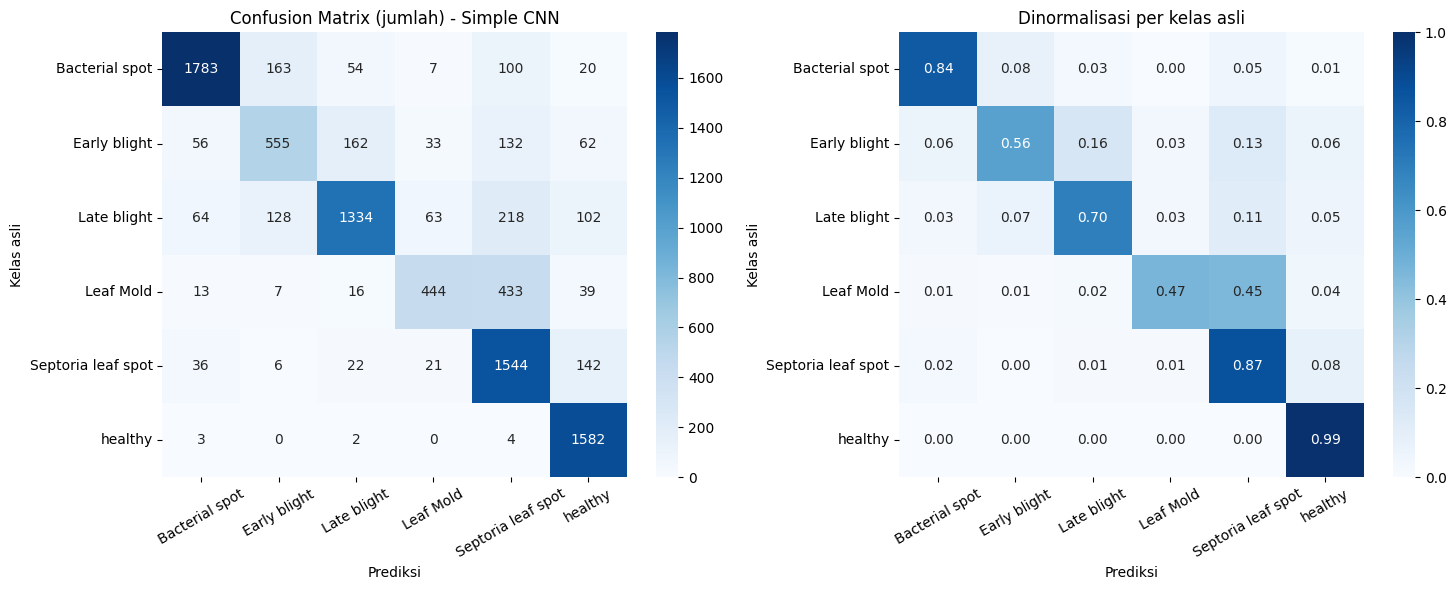

--- Classification report: Simple CNN ---


,precision,recall,f1-score,support
Bacterial spot,0.9120,0.8383,0.8736,2127.0000
Early blight,0.6461,0.5550,0.5971,1000.0000
Late blight,0.8390,0.6988,0.7625,1909.0000
Leaf Mold,0.7817,0.4664,0.5842,952.0000
Septoria leaf spot,0.6351,0.8718,0.7349,1771.0000
healthy,0.8125,0.9943,0.8943,1591.0000
accuracy,0.7745,0.7745,0.7745,0.7745
macro avg,0.7711,0.7374,0.7411,9350.0000
weighted avg,0.7860,0.7745,0.7691,9350.0000


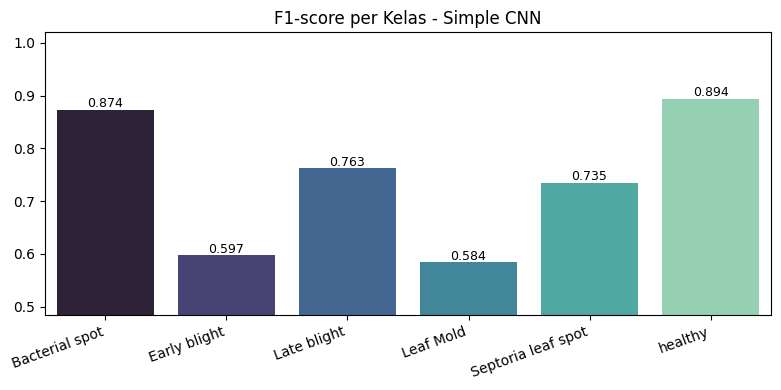

Kesalahan terbanyak Simple CNN (asli -> prediksi):
  Leaf Mold -> Septoria leaf spot: 433 gambar
  Late blight -> Septoria leaf spot: 218 gambar
  Bacterial spot -> Early blight: 163 gambar
  Early blight -> Late blight: 162 gambar
  Septoria leaf spot -> healthy: 142 gambar
Total salah: 2108 dari 9350


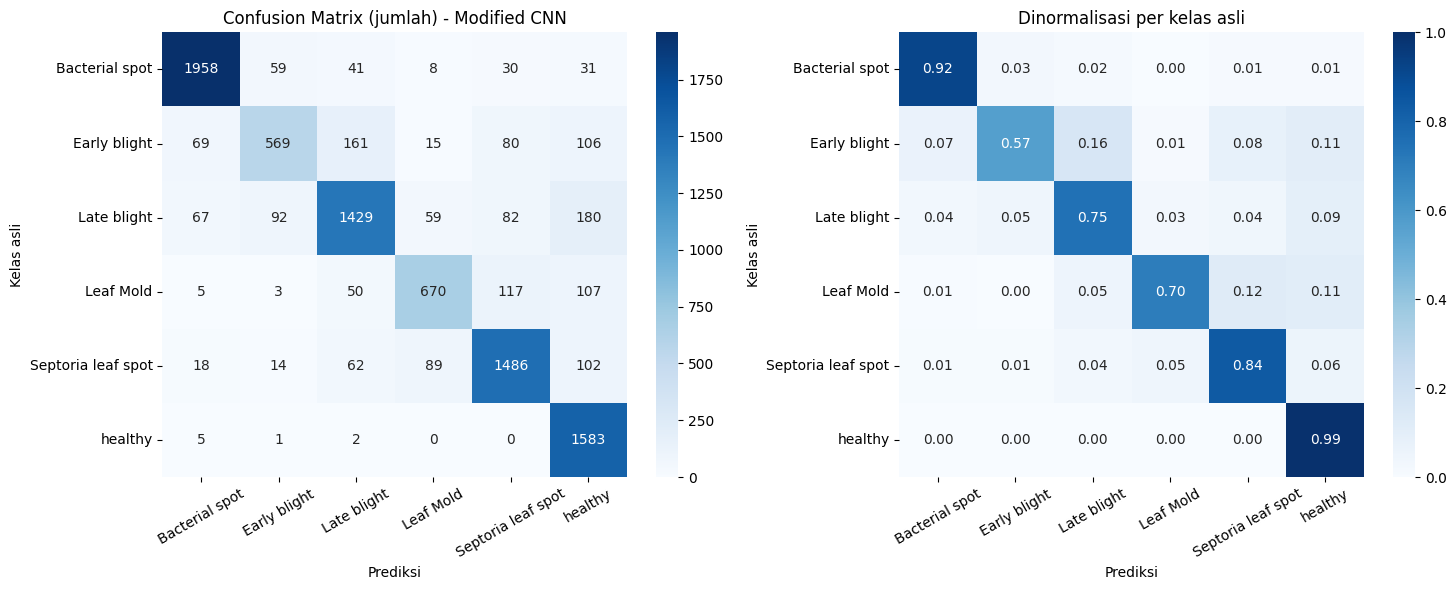

--- Classification report: Modified CNN ---


,precision,recall,f1-score,support
Bacterial spot,0.9227,0.9205,0.9216,2127.000
Early blight,0.7710,0.5690,0.6548,1000.000
Late blight,0.8189,0.7486,0.7822,1909.000
Leaf Mold,0.7967,0.7038,0.7474,952.000
Septoria leaf spot,0.8279,0.8391,0.8334,1771.000
healthy,0.7506,0.9950,0.8557,1591.000
accuracy,0.8230,0.8230,0.8230,0.823
macro avg,0.8146,0.7960,0.7992,9350.000
weighted avg,0.8252,0.8230,0.8189,9350.000


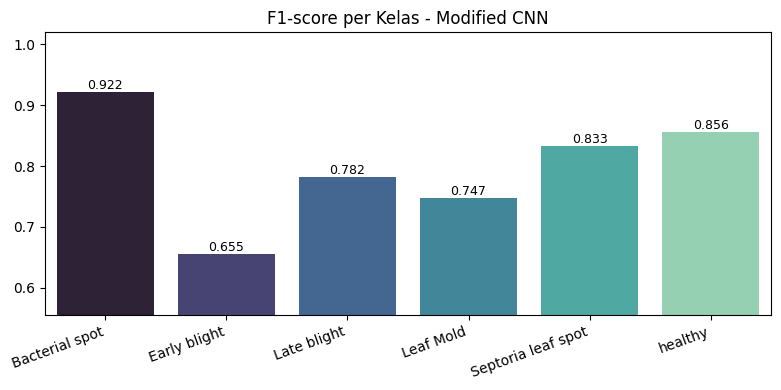

Kesalahan terbanyak Modified CNN (asli -> prediksi):
  Late blight -> healthy: 180 gambar
  Early blight -> Late blight: 161 gambar
  Leaf Mold -> Septoria leaf spot: 117 gambar
  Leaf Mold -> healthy: 107 gambar
  Early blight -> healthy: 106 gambar
Total salah: 1655 dari 9350


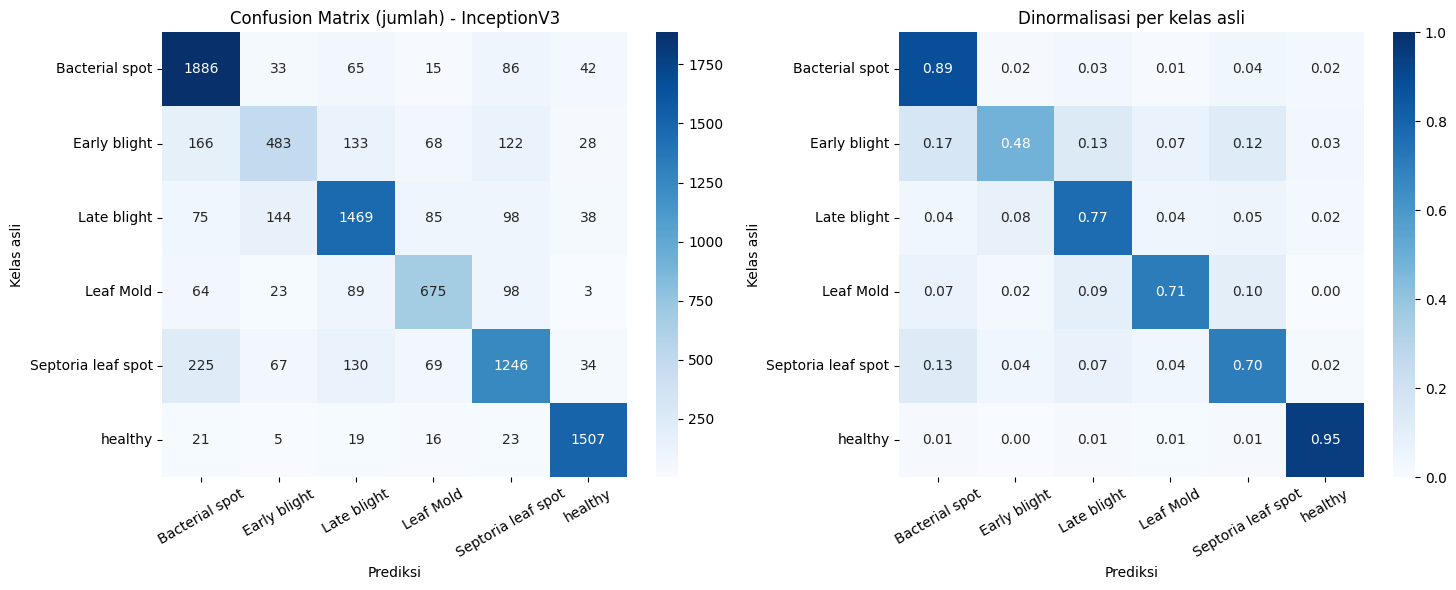

--- Classification report: InceptionV3 ---


,precision,recall,f1-score,support
Bacterial spot,0.7739,0.8867,0.8265,2127.0000
Early blight,0.6397,0.4830,0.5504,1000.0000
Late blight,0.7711,0.7695,0.7703,1909.0000
Leaf Mold,0.7274,0.7090,0.7181,952.0000
Septoria leaf spot,0.7448,0.7036,0.7236,1771.0000
healthy,0.9122,0.9472,0.9294,1591.0000
accuracy,0.7771,0.7771,0.7771,0.7771
macro avg,0.7615,0.7498,0.7530,9350.0000
weighted avg,0.7723,0.7771,0.7725,9350.0000


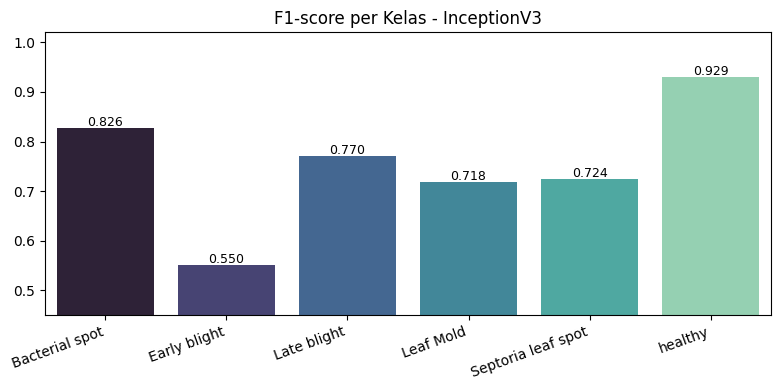

Kesalahan terbanyak InceptionV3 (asli -> prediksi):
  Septoria leaf spot -> Bacterial spot: 225 gambar
  Early blight -> Bacterial spot: 166 gambar
  Late blight -> Early blight: 144 gambar
  Early blight -> Late blight: 133 gambar
  Septoria leaf spot -> Late blight: 130 gambar
Total salah: 2084 dari 9350
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
def analisis_kelas(algo, top_n=5):
    yt, yp = np.array(RESULT[algo]['y_true']), np.array(RESULT[algo]['y_pred'])
    cm = confusion_matrix(yt, yp, labels=range(len(short)))
    cmn = cm / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=short, yticklabels=short, ax=axes[0])
    axes[0].set_title(f"Confusion Matrix (jumlah) - {NAMA[algo]}")
    sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=short, yticklabels=short, ax=axes[1])
    axes[1].set_title("Dinormalisasi per kelas asli")
    for a_ in axes:
        a_.set_xlabel("Prediksi"); a_.set_ylabel("Kelas asli"); a_.tick_params(axis='x', rotation=30)
    plt.tight_layout(); plt.savefig(f"fig5_confusion_algo{algo}.png", dpi=150); plt.show()

    rep = pd.DataFrame(classification_report(yt, yp, target_names=short, output_dict=True, zero_division=0)).T
    print(f"--- Classification report: {NAMA[algo]} ---"); display(rep.round(4))
    f1c = rep.loc[short, "f1-score"]
    plt.figure(figsize=(8, 4))
    ax = sns.barplot(x=short, y=f1c.values, hue=short, palette="mako", legend=False)
    for i, v in enumerate(f1c.values): ax.text(i, v + 0.005, f"{v:.3f}", ha='center', fontsize=9)
    plt.ylim(max(0, f1c.min() - 0.1), 1.02); plt.xticks(rotation=20, ha='right')
    plt.title(f"F1-score per Kelas - {NAMA[algo]}"); plt.tight_layout()
    plt.savefig(f"fig6_f1_algo{algo}.png", dpi=150); plt.show()

    pairs = [(short[i], short[j], int(cm[i, j])) for i in range(len(short)) for j in range(len(short)) if i != j and cm[i, j] > 0]
    pairs = sorted(pairs, key=lambda x: -x[2])[:top_n]
    print(f"Kesalahan terbanyak {NAMA[algo]} (asli -> prediksi):")
    for a_, b_, n in pairs: print(f"  {a_} -> {b_}: {n} gambar")
    print("Total salah:", int((yt != yp).sum()), "dari", len(yt))
    return f1c, pairs

ANALISIS = {a: analisis_kelas(a) for a in RESULT}

## 9. Soal 7 - Ringkasan angka untuk bahan jawaban

In [ ]:
for a in RESULT:
    f1c, pairs = ANALISIS[a]
    H = RESULT[a]['hist']
    gap = np.mean([h['accuracy'][-1] - h['val_accuracy'][-1] for h in H])
    ep = np.mean([len(h['loss']) for h in H])
    sub = tab[tab.Algoritma == NAMA[a]]
    print(f"=== {NAMA[a]} ===")
    print(f"Accuracy rata-rata : {sub.Accuracy.mean():.4f} ± {sub.Accuracy.std():.4f} (min {sub.Accuracy.min():.4f}, maks {sub.Accuracy.max():.4f})")
    print(f"F1 makro rata-rata : {sub.F1.mean():.4f}")
    print(f"Kelas terbaik      : {f1c.idxmax()} (F1 {f1c.max():.3f}); terburuk: {f1c.idxmin()} (F1 {f1c.min():.3f})")
    print(f"Kesalahan terbanyak: {pairs[0][0]} -> {pairs[0][1]} ({pairs[0][2]} gambar)" if pairs else "Tidak ada kesalahan")
    print(f"Selisih akurasi train - val (epoch akhir, rata-rata fold): {gap:+.4f}  | rata-rata epoch berjalan: {ep:.1f}")
    print()

=== Simple CNN ===
Accuracy rata-rata : 0.7745 ± 0.0343 (min 0.7144, maks 0.7968)
F1 makro rata-rata : 0.7397
Kelas terbaik      : healthy (F1 0.894); terburuk: Leaf Mold (F1 0.584)
Kesalahan terbanyak: Leaf Mold -> Septoria leaf spot (433 gambar)
Selisih akurasi train - val (epoch akhir, rata-rata fold): +0.1399  | rata-rata epoch berjalan: 9.0

=== Modified CNN ===
Accuracy rata-rata : 0.8230 ± 0.0316 (min 0.7738, maks 0.8524)
F1 makro rata-rata : 0.7984
Kelas terbaik      : Bacterial spot (F1 0.922); terburuk: Early blight (F1 0.655)
Kesalahan terbanyak: Late blight -> healthy (180 gambar)
Selisih akurasi train - val (epoch akhir, rata-rata fold): +0.1496  | rata-rata epoch berjalan: 8.8

=== InceptionV3 ===
Accuracy rata-rata : 0.7771 ± 0.0043 (min 0.7727, maks 0.7840)
F1 makro rata-rata : 0.7532
Kelas terbaik      : healthy (F1 0.929); terburuk: Early blight (F1 0.550)
Kesalahan terbanyak: Septoria leaf spot -> Bacterial spot (225 gambar)
Selisih akurasi train - val (epoch akhir, 

### Panduan menulis jawaban Soal 7
- **Kelebihan:** akurasi dan F1 rata-rata tinggi, std antar fold kecil (model stabil), augmentasi membantu generalisasi, InceptionV3 pretrained mempercepat konvergensi.
- **Keterbatasan:** kelas dengan F1 terendah dan pasangan kelas yang sering tertukar (penyakit dengan gejala mirip), ketidakseimbangan jumlah data antar kelas (lihat Bagian 3), gambar PlantVillage berlatar seragam sehingga belum tentu sebaik itu pada foto lapangan, resolusi hanya 128x128, backbone InceptionV3 dibekukan (tidak di-fine-tune).
Sesuaikan kalimatnya dengan angka yang benar-benar keluar dari Bagian 9.